In [4]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.21.0) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.8.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post117+g266f496, need >=(0, 19, 0), <(0, 22, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [5]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [6]:
np.random.choice([0.7, 0.55, 0.75])

np.float64(0.55)

In [7]:
[[1, 1, 1]]  * 2

[[1, 1, 1], [1, 1, 1]]

In [419]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: int,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg = 0,
        firing_prop = 0.05,
        interp_factor: int = 2,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: int

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * 1)) + 0.01
    # print(clean)

    x = 0
    a_options = [0.7]#, 0.6, 0.55]
    a_decay = 0.7
    a_rise = 1 / a_decay

    A = np.outer(np.ones(n_components) + np.random.normal(scale=0.1, size=n_components), np.ones(n_components) + np.random.normal(scale=0.1, size=n_components))
    print(A)
    
    b = 0

    rise_time = 20
    
    n_rise = 15

    max_amplitude = 2.0

    spikes = list()

    spikes = (np.random.rand(n_timepoints) < firing_prop).astype(bool)
    
    # for i in range(n_components):
    #     spikes.append(spikes_array)

    for n_c in range(n_components):
        for i in range(2, n_timepoints):
            if spikes[i]:
                a = a_rise
                a_decay = np.random.choice(a_options)
                n_rise = rise_time
            elif n_rise > 0:
                if clean[0, i - 1] > max_amplitude:
                    a = a_decay
                    n_rise = 0
                else:
                    a = a_rise
                    n_rise -= 1
            else:
                a = a_decay
            # clean[n_c, i] = a * clean[n_c, i - 1] + np.abs(np.random.normal(scale=0.01, size=1))
            
            clean[:, i] = ((a * A) / A.shape[0]) @ clean[:, i - 1] + np.abs(np.random.normal(scale=0.01, size=n_components))

        # x_ = np.arange(0, n_timepoints * interp_factor)
        # xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        # clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    # n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [597]:
n_components = 6

In [606]:
np.random.seed(1)
X, _ = generate_data(
    n_timepoints=1000,
    n_components=n_components,
    noise=0.001,
    n_pixels=1,
    n_pixels_bg=0,
    interp_factor=1,
    firing_prop=0.05,
)

[[1.36525748 1.07394922 1.19952074 1.13344686 1.33239501 0.92295667]
 [1.10263154 0.8673604  0.96877653 0.91541286 1.07609061 0.74541333]
 [1.1124484  0.87508261 0.97740166 0.92356289 1.08567118 0.75204984]
 [1.04846303 0.82474996 0.92118386 0.87044177 1.02322597 0.70879373]
 [1.27612167 1.00383253 1.12120566 1.05944566 1.24540475 0.86269808]
 [0.90416979 0.71124491 0.79440723 0.75064845 0.88240594 0.611247  ]]


In [607]:
n_pixels = n_components

In [608]:
X.shape

(6, 1000)

In [609]:
for i in range(1, n_components):
    X[i, :-i] = X[i, i:]

In [610]:
X = X[:]# 230:300]

In [611]:
peak_ixs = slice(60, 120)

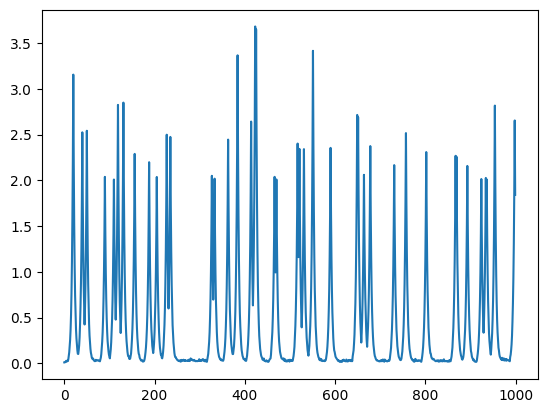

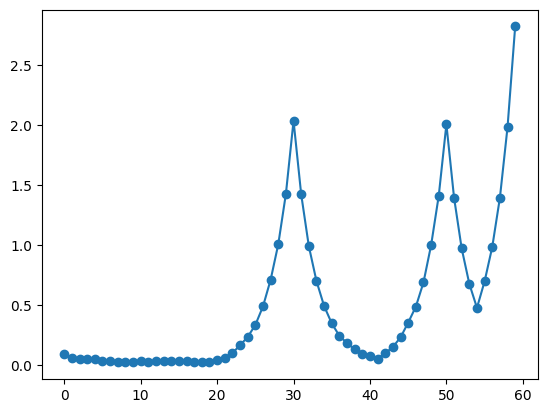

In [612]:
plt.plot(X[0])
# plt.plot(X[1])
plt.show()
plt.plot(X.ravel()[peak_ixs])
plt.scatter(np.arange(0, peak_ixs.start), X.ravel()[peak_ixs])

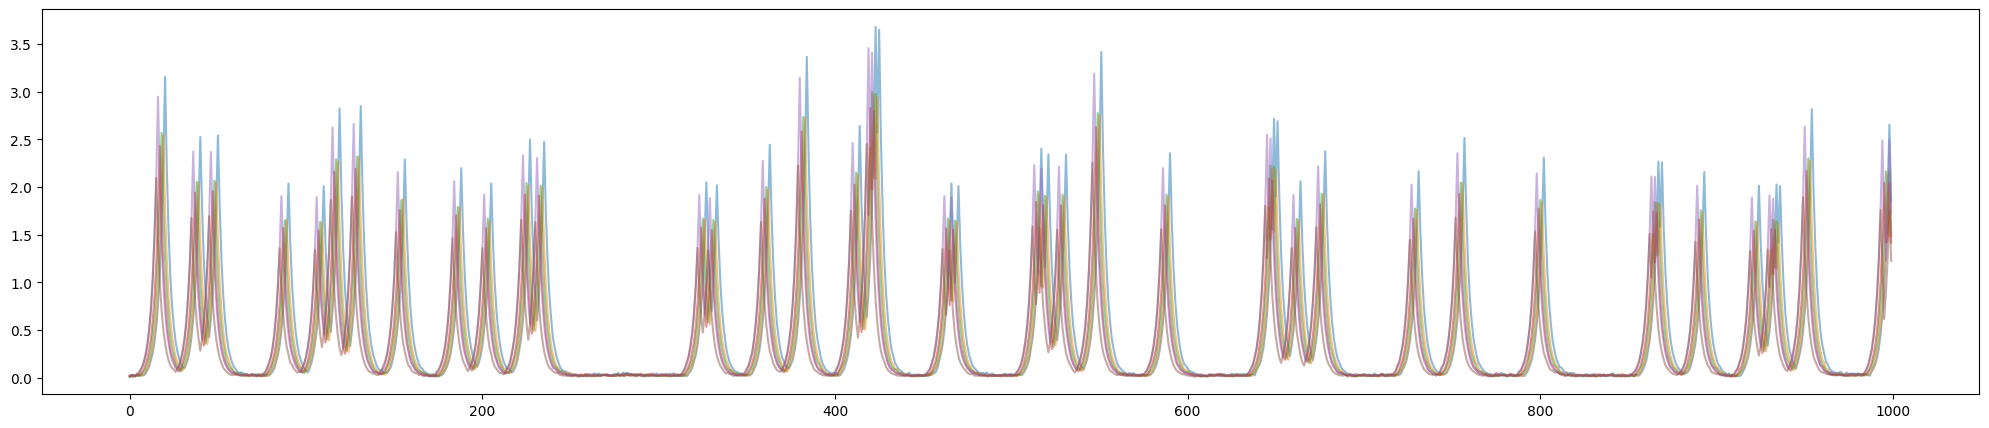

In [613]:
fig = plt.figure(figsize=(25, 5))
plt.plot(X.T, alpha=0.5)

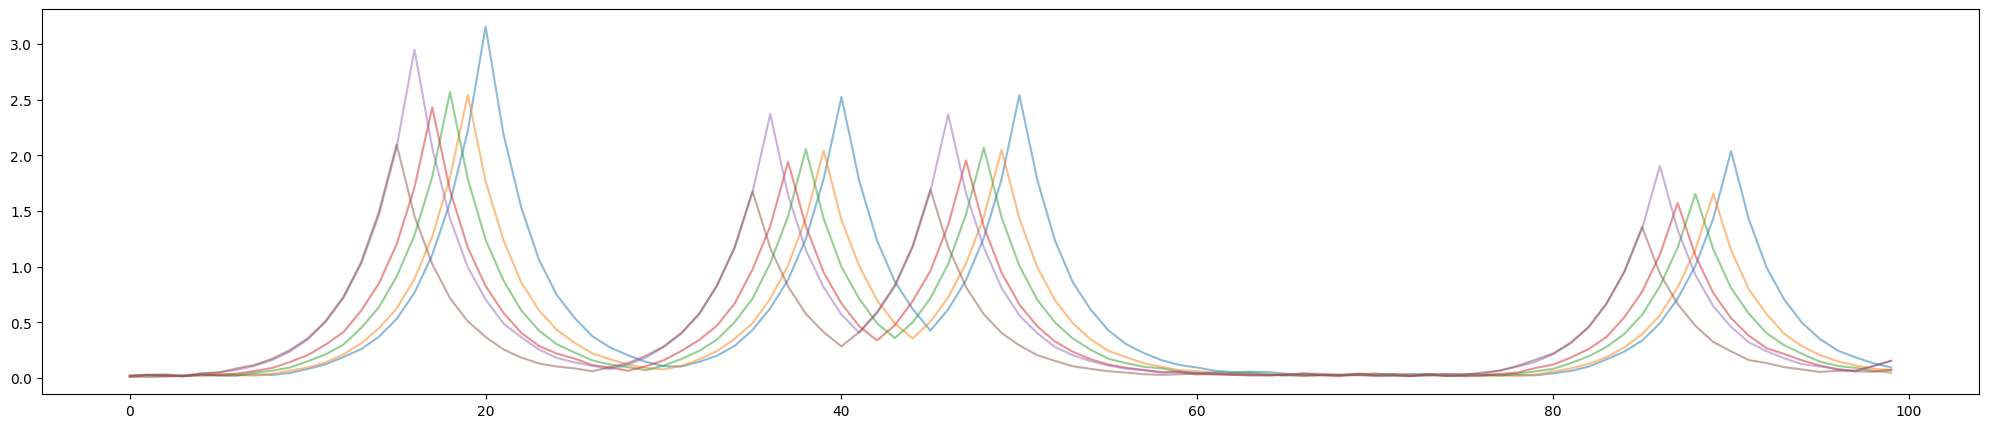

In [614]:
fig = plt.figure(figsize=(25, 5))
plt.plot(X[:, :100].T, alpha=0.5)

<Axes: >

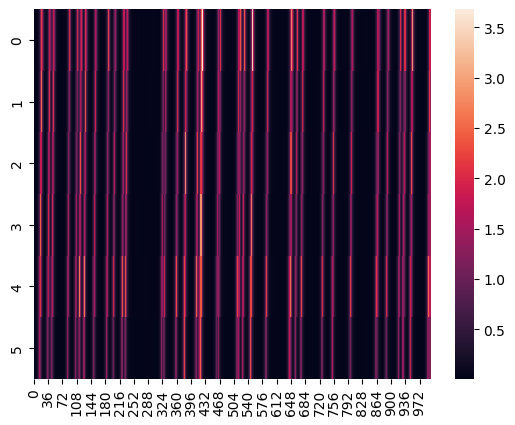

In [615]:
sns.heatmap(X)

In [616]:
X.shape

(6, 1000)

In [617]:
lag = 4

Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X[i, :lag * 2], X[i, lag * 2 - 1:]))

H = np.zeros((lag * 2 * n_pixels, X.shape[1] - (lag * 2) + 1))
for i, H_i in enumerate(Hs):
    H[i::n_pixels] = H_i

<Axes: >

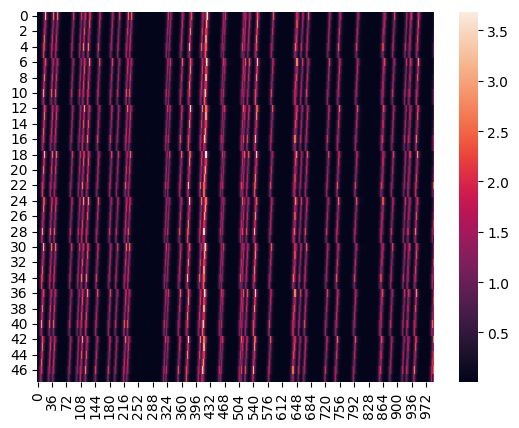

In [618]:
sns.heatmap(H)

<Axes: >

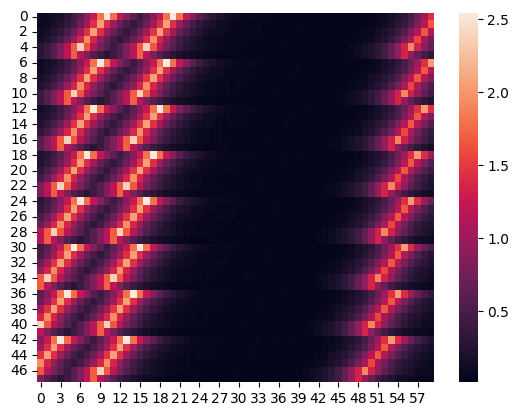

In [619]:
sns.heatmap(H[:, 30:90])

In [620]:
mu0 = np.mean(H[:lag * n_pixels])
mu1 = np.mean(H[lag * n_pixels:])

In [621]:
H[:lag * n_pixels] -= mu0
H[lag * n_pixels:] -= mu1

In [622]:
cov = (H @ H.T) / H.shape[1]

<Axes: >

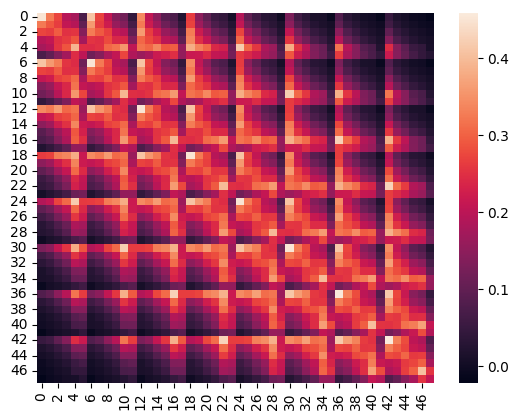

In [623]:
sns.heatmap(cov)

In [624]:
cov

array([[ 0.45012761,  0.32425838,  0.27221801, ..., -0.00518811,
        -0.00837473, -0.02110013],
       [ 0.32425838,  0.2898763 ,  0.26512959, ...,  0.00500225,
        -0.00365472, -0.00617178],
       [ 0.27221801,  0.26512959,  0.29456183, ...,  0.0137229 ,
         0.00537064, -0.00097815],
       ...,
       [-0.00518811,  0.00500225,  0.0137229 , ...,  0.2720585 ,
         0.2983815 ,  0.17926055],
       [-0.00837473, -0.00365472,  0.00537064, ...,  0.2983815 ,
         0.40533861,  0.25433913],
       [-0.02110013, -0.00617178, -0.00097815, ...,  0.17926055,
         0.25433913,  0.20844605]])

In [625]:
past = H[:lag * n_pixels]
future = H[lag * n_pixels:]

In [626]:
past.shape

(24, 993)

In [627]:
PP = past @ past.T / past.shape[1]
FF = future @ future.T / future.shape[1]
PF = past @ future.T / past.shape[1]

<Axes: >

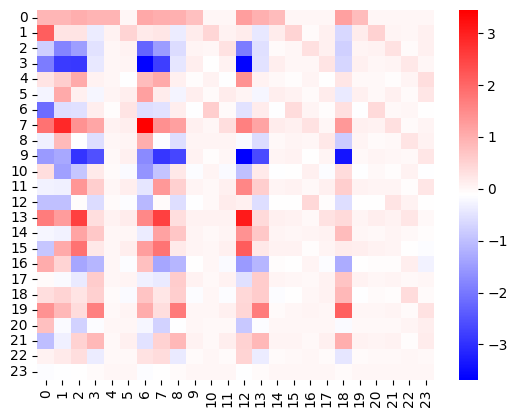

In [628]:
sns.heatmap(np.linalg.inv(FF) @ (future @ past.T / past.shape[1]), cmap="bwr")

In [629]:
from deeptime.numeric import spd_inv_sqrt

In [630]:
PP_inv_sqrt = linalg.inv(linalg.sqrtm(PP))
FF_inv_sqrt = linalg.inv(linalg.sqrtm(FF))

K_bar = PP_inv_sqrt @ PF @ FF_inv_sqrt

<Axes: >

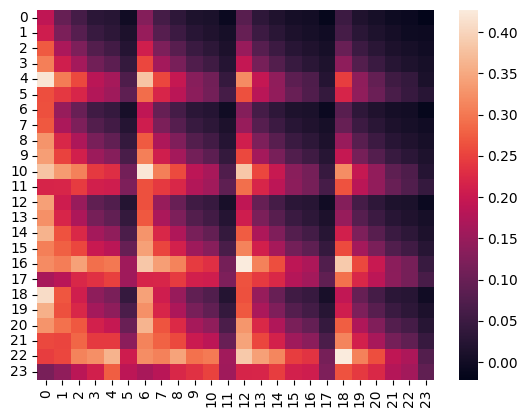

In [631]:
sns.heatmap(PF)

<Axes: >

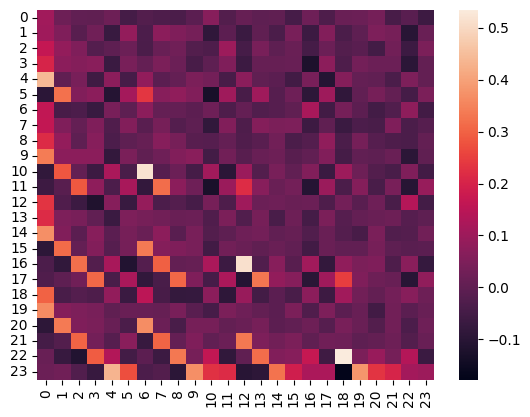

In [632]:
sns.heatmap(K_bar)

In [633]:
U, S, Vh = np.linalg.svd(K_bar,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec = PP_inv_sqrt @ U
right_vec = FF_inv_sqrt @ Vh.T

# projection of data onto left and right singular vectors
# proj_left = past.T @ left_vec
# proj_right = future.T @ right_vec

proj_left = left_vec.T @ past
proj_right = right_vec.T @ future

Text(0.5, 1.0, 'right')

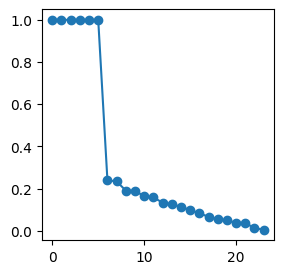

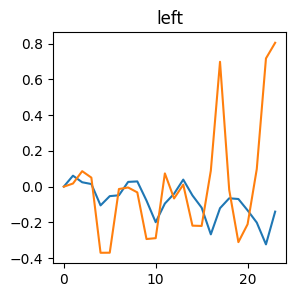

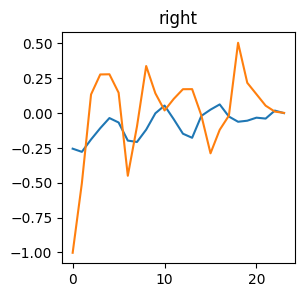

In [634]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec[:, :2])
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec[:, :2])
plt.title("right")

In [635]:
S / S.max()

array([1.        , 0.99993573, 0.99956351, 0.9992507 , 0.9988008 ,
       0.9982582 , 0.23983968, 0.23482803, 0.19130717, 0.18854661,
       0.16555004, 0.1585199 , 0.13429717, 0.12576362, 0.11497604,
       0.09865908, 0.08395672, 0.0670863 , 0.05508323, 0.05027468,
       0.03876709, 0.03685839, 0.01441847, 0.00557733])

In [636]:
from itertools import product

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='800.0px', css_width='900.0px')
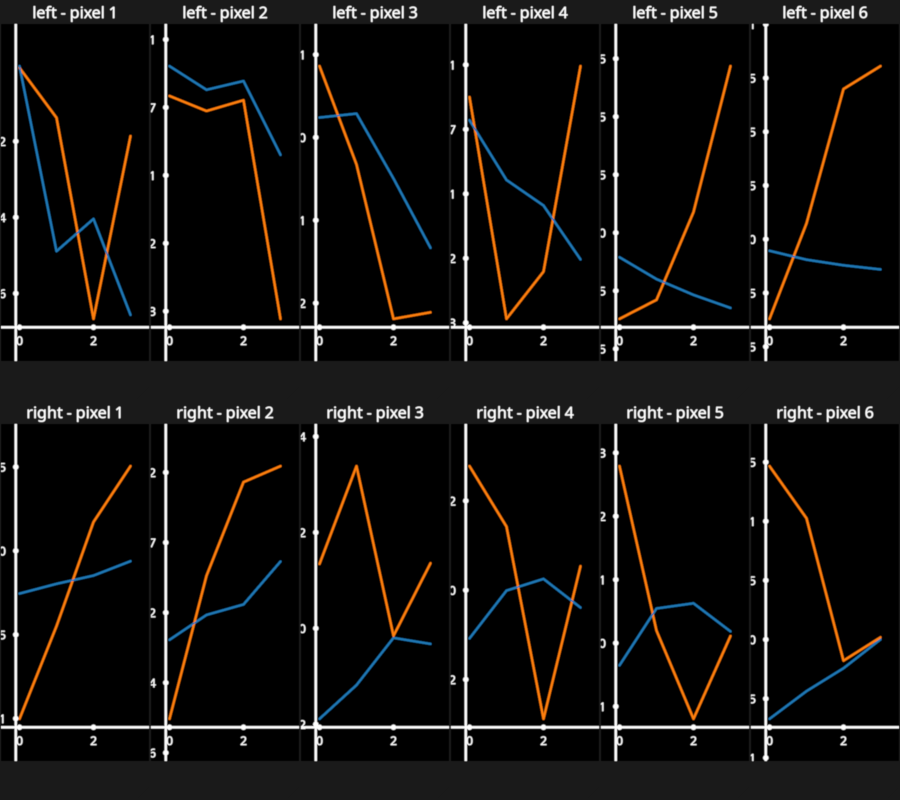

In [637]:
fig = fpl.Figure(
    shape=(2, n_pixels), 
    size=(900, 800),
    names=[f"{n} - pixel {i}" for n, i in product(["left", "right"], range(1, n_pixels + 1))]
)

for i in range(n_pixels):
    fig[0, i].add_line_collection(left_vec[i::n_pixels, :2].T, cmap="tab10")

for i in range(n_pixels):
    fig[1, i].add_line_collection(right_vec[i::n_pixels, :2].T, cmap="tab10")

fig.show(maintain_aspect=False)

In [638]:
X.ravel().shape

(6000,)

Text(0.5, 1.0, 'proj left, past')

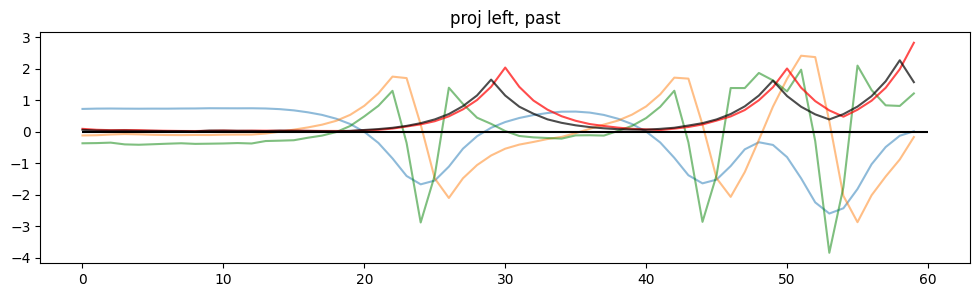

In [656]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_left.T[peak_ixs, :2], alpha=0.5)
plt.plot(proj_left.T[peak_ixs, 2], alpha=0.5, c="g")
plt.plot(X[0].ravel()[peak_ixs], c="r", alpha=0.7)
plt.plot(X[1].ravel()[peak_ixs], c="k", alpha=0.7)
plt.hlines(0, 0, peak_ixs.start, colors="k")
plt.title("proj left, past")

Text(0.5, 1.0, 'proj right, future')

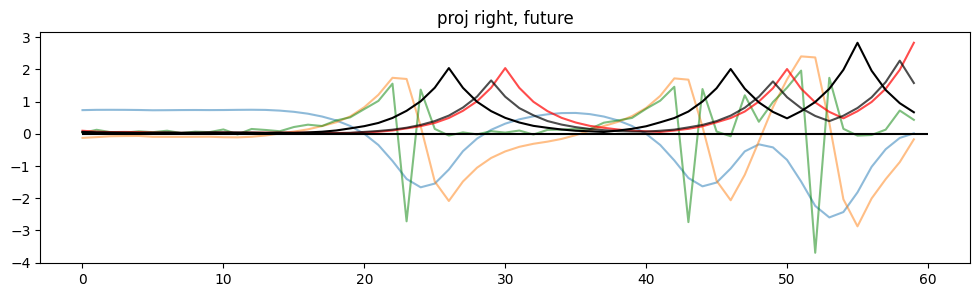

In [660]:
fig = plt.figure(figsize=(12, 3))
peak_ixs_f = slice(peak_ixs.start + lag, peak_ixs.stop + lag)
plt.plot(proj_right.T[peak_ixs, :2], alpha=0.5)
plt.plot(proj_left.T[peak_ixs, 5], alpha=0.5, c="g")
plt.plot(X[0].ravel()[peak_ixs], c="r", alpha=0.7)
plt.plot(X[1].ravel()[peak_ixs], c="k", alpha=0.7)
plt.plot(X.ravel()[peak_ixs_f], c="k")
plt.hlines(0, 0, peak_ixs.start, colors="k")
plt.title("proj right, future")

In [233]:
from itertools import product

In [235]:
for left_sign, right_sign in product(["+", "-"], ["+", "-"]):
    r1 = proj_left.T[:, 2].copy()
    r2 = proj_right.T[:, 2].copy()
    
    if left_sign == "+":
        r1[r1 < 0] = 0
    elif left_sign == "-":
        r1[r1 > 0] = 0
        
    if right_sign == "+":
        r2[r2 < 0] = 0
    elif right_sign == "-":
        r2[r2 > 0] = 0

    r1 = np.abs(r1)
    r2 = np.abs(r2)

    print(left_sign, right_sign, np.dot(r1, r2))

+ + 222.7676174855888
+ - 143.03635873790284
- + 45.26275500095031
- - 207.60708603872524


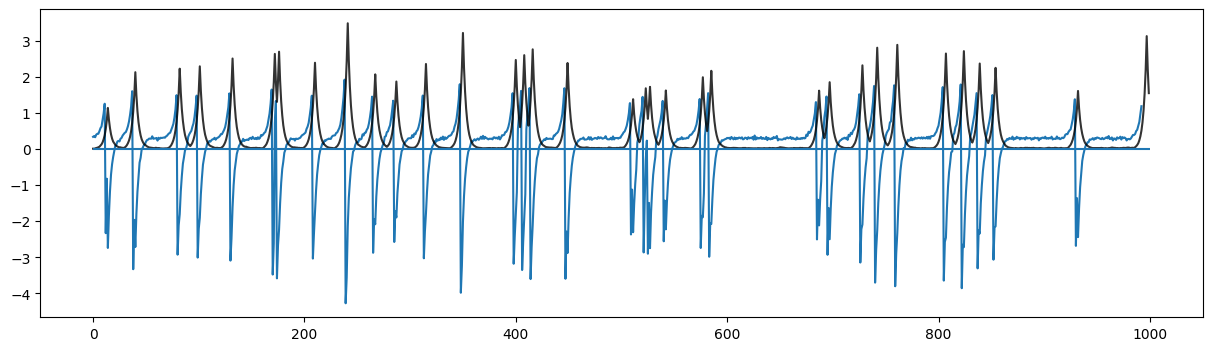

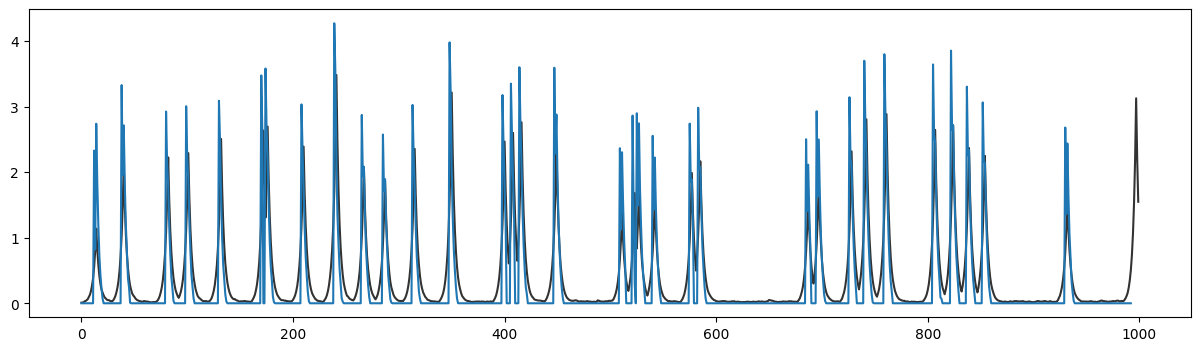

In [236]:
fig = plt.figure(figsize=(15, 4))
plt.plot(proj_left.T[:, 2])
plt.plot(X.mean(axis=0), c="k", alpha=0.8)
plt.hlines(y=0, xmin=0, xmax=X.shape[1])
plt.show()

fig = plt.figure(figsize=(15, 4))
r1 = proj_left.T[:, 2].copy()
r1[r1 > 0] = 0
r1 = np.abs(r1)

# r2 = proj_left.T[:, 1].copy()
# r2[r2 > 0] = 0
# r2 = np.abs(r2)

plt.plot(X.mean(axis=0), c="k", alpha=0.8)
plt.plot(r1)
# plt.plot(r2)

# r1 = P_1-

# r2 = F_1+

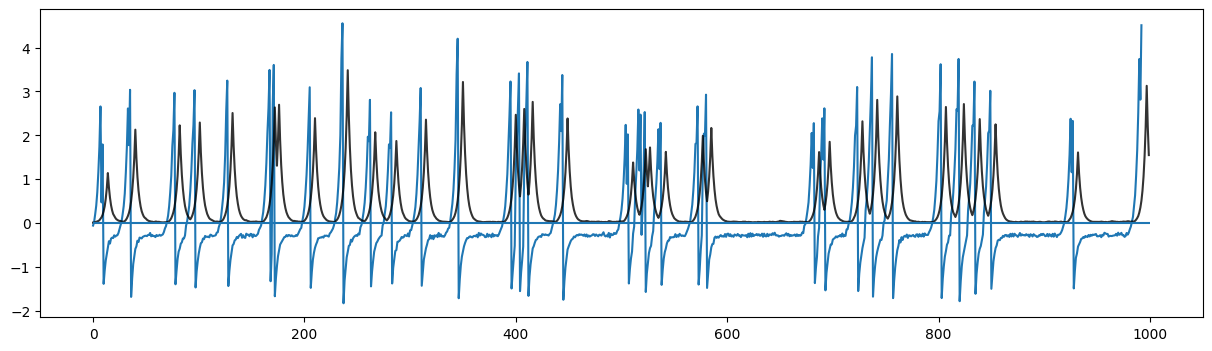

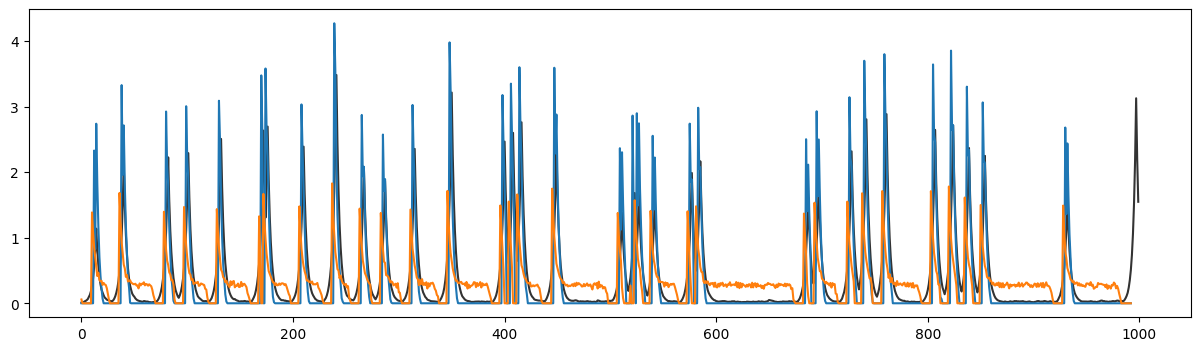

In [237]:
fig = plt.figure(figsize=(15, 4))
plt.plot(proj_right.T[:, 2])
plt.plot(X.mean(axis=0), c="k", alpha=0.8)
plt.hlines(y=0, xmin=0, xmax=X.shape[1])
plt.show()

# fig = plt.figure(figsize=(15, 4))
# r1 = proj_right.T[:, 1].copy()
# r1[r1 < 0] = 0

r2 = proj_right.T[:, 2].copy()
r2[r2 > 0] = 0
r2 = np.abs(r2)

fig = plt.figure(figsize=(15, 4))
plt.plot(X.mean(axis=0), c="k", alpha=0.8)
plt.plot(r1)
plt.plot(r2)

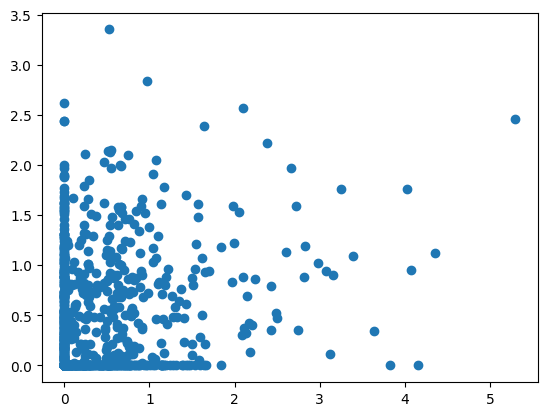

In [61]:
plt.scatter(r1, r2)

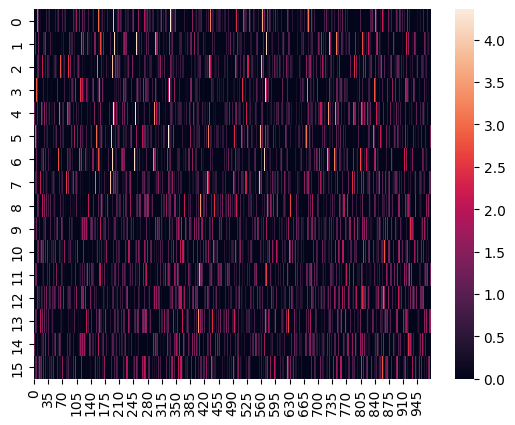

<Axes: >

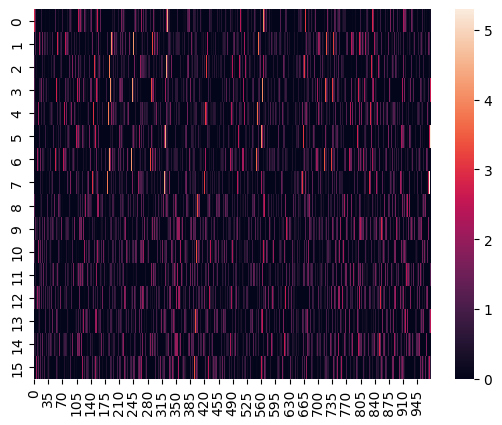

In [62]:
lag = 8

r1_ = scipy.linalg.hankel(r1[:lag * 2], r1[lag * 2 - 1:])
r2_ = scipy.linalg.hankel(r2[:lag * 2], r2[lag * 2 - 1:])

A = np.vstack([r1_[:lag], r2_[:lag]])
B = np.vstack([r1_[lag:], r2_[lag:]])

sns.heatmap(A)
plt.show()

sns.heatmap(B)

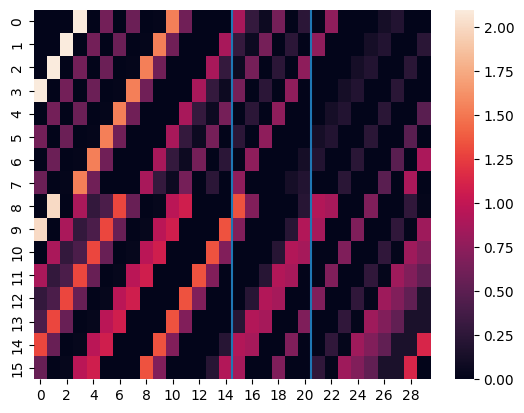

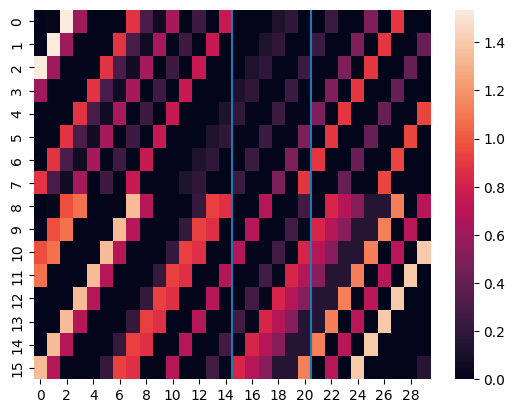

In [63]:
ax = sns.heatmap(A[:, 20:50])
ax.vlines(21, ymin=0, ymax=lag*10)
ax.vlines(15, ymin=0, ymax=lag*10)
plt.show()

ax = sns.heatmap(B[:, 20:50])
ax.vlines(15, ymin=0, ymax=lag*10)
ax.vlines(21, ymin=0, ymax=lag*10)

In [64]:
A -= A.mean()
B -= B.mean()

In [65]:
AA = A @ A.T / A.shape[1]
BB = B @ B.T / B.shape[1]
AB = A @ B.T / A.shape[1]

In [66]:
AA_inv_sqrt = linalg.inv(linalg.sqrtm(AA))
BB_inv_sqrt = linalg.inv(linalg.sqrtm(BB))

K_bar2 = AA_inv_sqrt @ AB @ BB_inv_sqrt

In [67]:
U2, S2, Vh2 = np.linalg.svd(K_bar2,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec2 = AA_inv_sqrt @ U2
right_vec2 = BB_inv_sqrt @ Vh2.T

proj_left2 = left_vec2.T @ A
proj_right2 = right_vec2.T @ B

Text(0.5, 1.0, 'right')

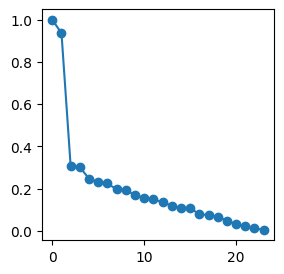

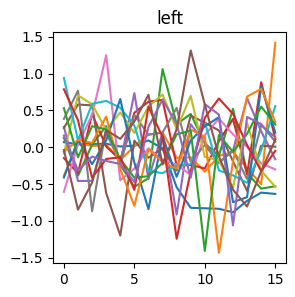

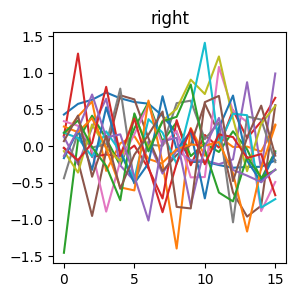

In [68]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec2)
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec2)
plt.title("right")

Text(0.5, 1.0, 'proj2 left')

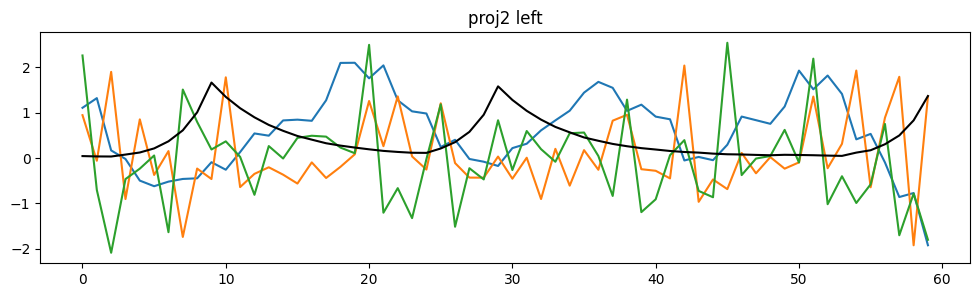

In [69]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_left2[:3].T[peak_ixs])
plt.plot(X.ravel()[peak_ixs], c="k")
plt.title("proj2 left")

Text(0.5, 1.0, 'proj2 right')

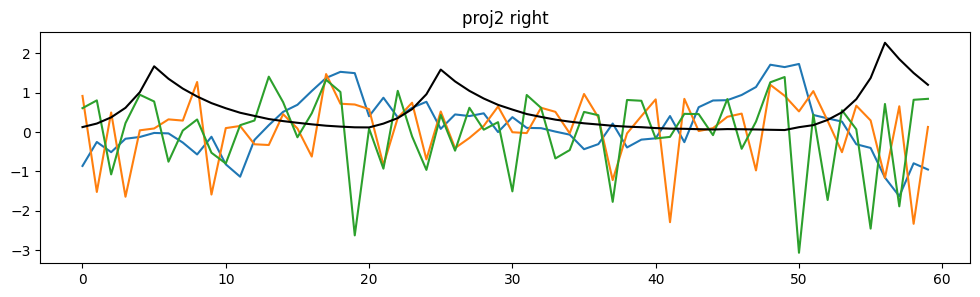

In [70]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_right2[:3].T[peak_ixs])
plt.plot(X.ravel()[peak_ixs_f], c="k")
plt.title("proj2 right")

In [273]:
d1 = np.gradient(X.ravel()[lag:])
d1_scaled = (d1 / d1.max()) * proj_right2[1].max()

In [274]:
d1.shape

(492,)

In [275]:
proj_right2.shape

(16, 478)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='700.0px', css_width='2400.0px')
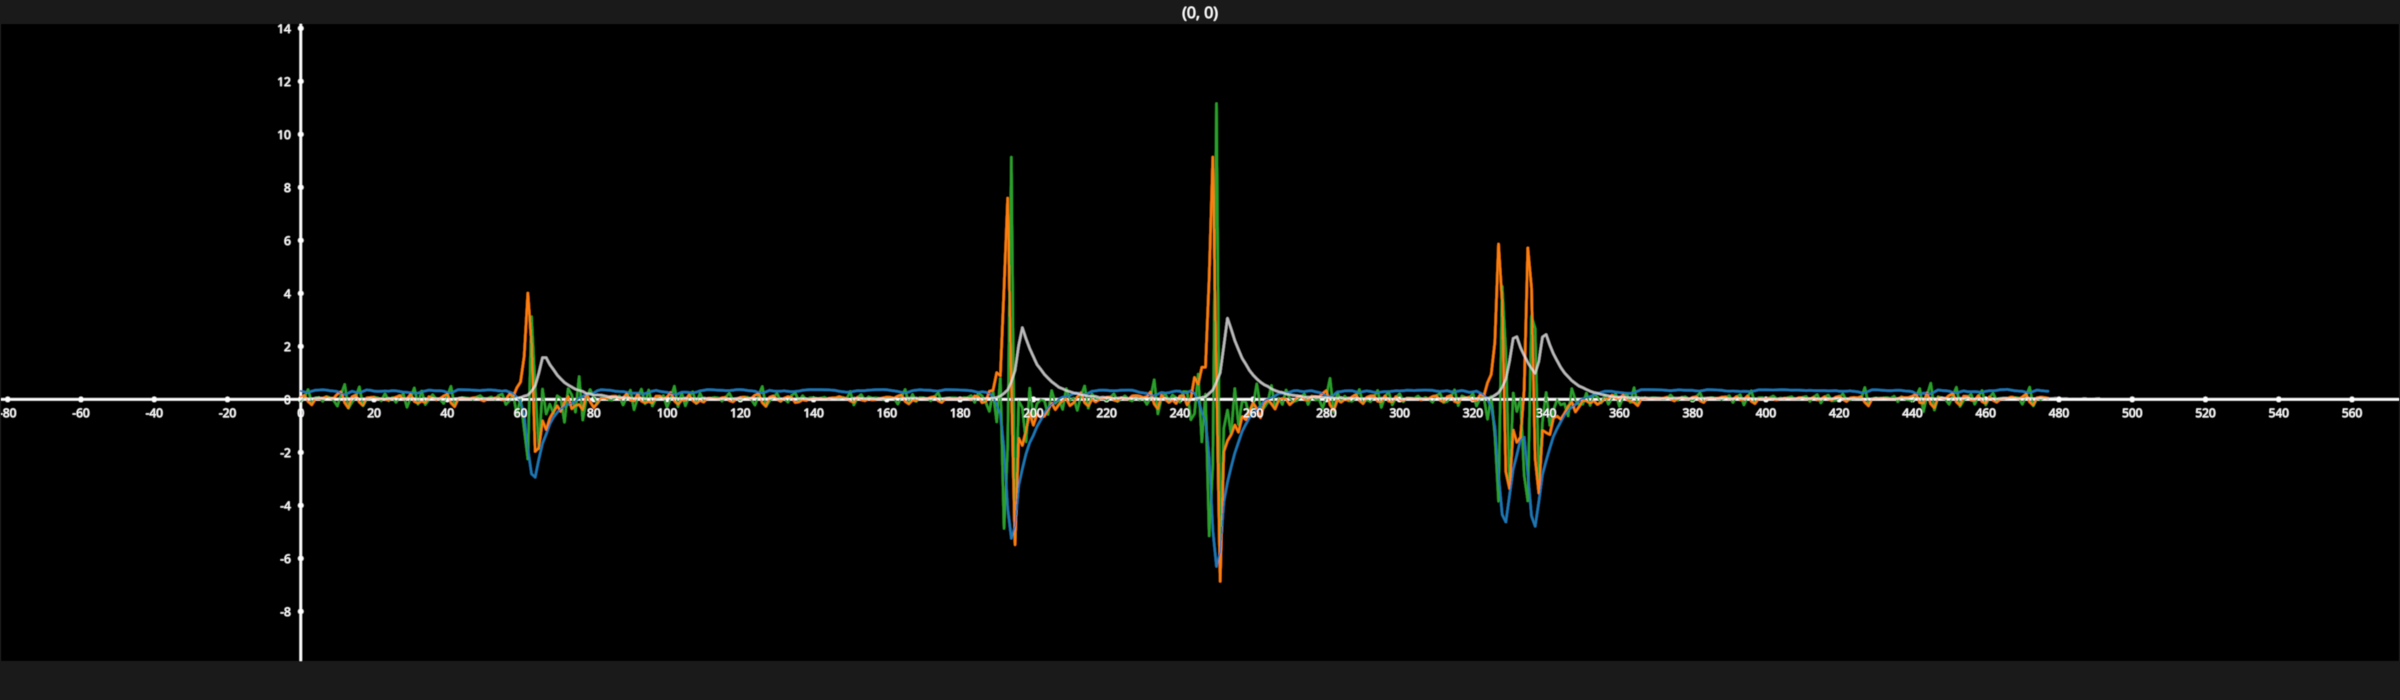

In [276]:
fig = fpl.Figure(size=(2400, 700))

fig[0, 0].add_line_collection(proj_right2[:3], cmap="tab10", alpha=0.8)
fig[0, 0].add_line(X.ravel()[lag:], alpha=0.5)
# fig[0, 0].add_line(d1_scaled, alpha=0.4, colors="r")

fig[0, 0].axes.intersection = (0, 0, 0)

fig.show(maintain_aspect=False)

In [277]:
proj_left2.shape

(16, 478)

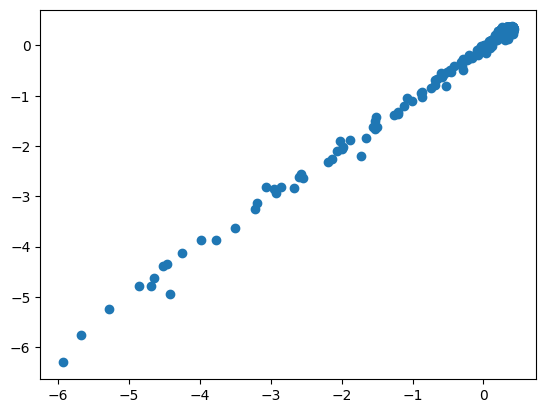

In [278]:
plt.scatter(proj_left2[0], proj_right2[0])

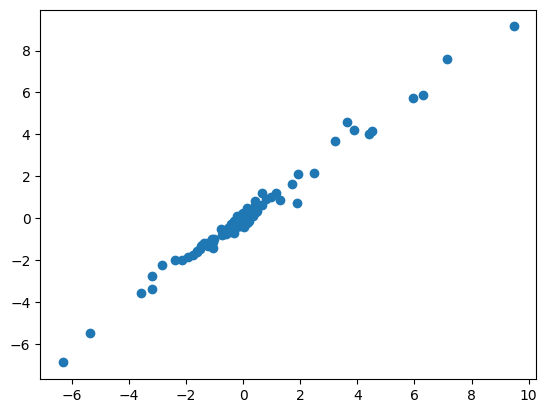

In [279]:
plt.scatter(proj_left2[1], proj_right2[1])

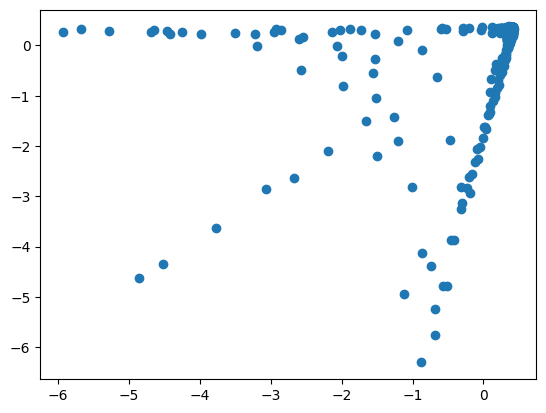

In [280]:
plt.scatter(proj_left2[0, lag:], proj_right2[0, :-lag])

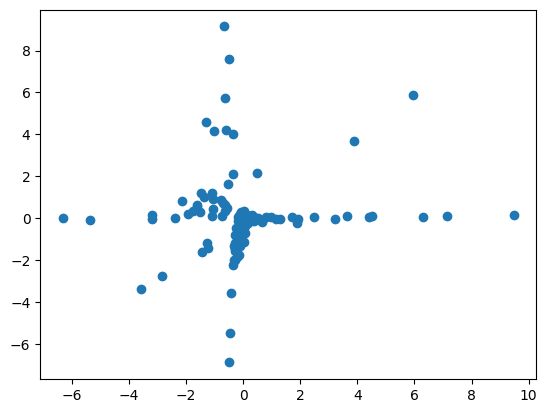

In [281]:
plt.scatter(proj_left2[1, lag:], proj_right2[1, :-lag])

In [282]:
proj_left2.shape

(16, 478)

In [283]:
d1_scaled.shape

(492,)

In [284]:
from ipywidgets import VBox

In [285]:
proj_left2.shape

(16, 478)

In [286]:
fig2 = fpl.Figure(
    shape=(2, 1),
    names=["pl", "pr"],
    controller_ids="sync",
    size=(2700, 700),
)

pl_graphic = fig2["pl"].add_line_collection(proj_left2[:3], cmap="tab10", alpha=0.8)
fig2["pl"].add_line(X.ravel()[lag:], alpha=0.5)
fig2["pl"].add_line(d1_scaled, alpha=0.4, colors="r")

sel1 = pl_graphic.add_linear_selector()

pr_graphic = fig2["pr"].add_line_collection(proj_right2[:3], cmap="tab10", alpha=0.8)
fig2["pr"].add_line(X.ravel()[lag:], alpha=0.5)
fig2["pr"].add_line(d1_scaled, alpha=0.4, colors="r")

sel2 = pr_graphic.add_linear_selector()

for subplot in fig2:
    subplot.axes.intersection = (0, 0, 0)
    subplot.axes.grids.xy.visible = True
    subplot.axes.auto_grid = False
    subplot.axes.grids.xy.minor_step = (0, 1)
    subplot.axes.grids.xy.major_step = (0, 5)

fig3 = fpl.Figure(
    shape=(1, 5),
    cameras=["3d", "2d", "2d", "2d", "2d"],
    names=["pl1-pl2-pr3", "pr1-pr2", "pl2-pr2-no-adjust", "pl1-pr1", "pl2-pr2"],
    size=(2700, 700)
)

r2_neg = proj_right2[2].copy()
r2_neg[r2_neg > 0] = 0

fig3["pl1-pl2-pr3"].add_scatter(np.column_stack([proj_left2[:2].T, r2_neg]), sizes=5, cmap="seismic", cmap_transform=d1[:proj_left2.shape[1]])
fig3["pr1-pr2"].add_scatter(proj_right2[:2].T, sizes=5, cmap="seismic", cmap_transform=d1[:proj_left2.shape[1]])
fig3["pl2-pr2-no-adjust"].add_scatter(np.column_stack([proj_left2[1], proj_right2[1]]), sizes=5, cmap="seismic", cmap_transform=d1[:proj_left2.shape[1]])
fig3["pl1-pr1"].add_scatter(np.column_stack([proj_left2[0, lag:], proj_right2[0, :-lag]]), sizes=5, cmap="seismic", cmap_transform=d1[:proj_left2.shape[1] - lag])
fig3["pl2-pr2"].add_scatter(np.column_stack([proj_left2[1, lag:], proj_right2[1, :-lag]]), sizes=5, cmap="seismic", cmap_transform=d1[:proj_left2.shape[1] - lag])

for subplot in fig3:
    subplot.axes.intersection = (0, 0, 0)

def update_pos(ev):
    value = ev.info["value"]

    for sel in [sel1, sel2]:
        sel.selection = value

    for subplot in fig3:
        sg = subplot.graphics[0]
        sg.sizes = 5
        sg.sizes[int(value)] = 15

for sel in [sel1, sel2]:
    sel.add_event_handler(update_pos, "selection")

def on_click(ev):
    index = ev.pick_info["vertex_index"]
    for sel in [sel1, sel2]:
        sel.selection = index

    for subplot in fig3:
        sg = subplot.graphics[0]
        sg.sizes = 5
        sg.sizes[index] = 15

for subplot in fig3:
    sg = subplot.graphics[0]
    sg.add_event_handler(on_click, "click")

VBox([fig2.show(maintain_aspect=False), fig3.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:266: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:266: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:278: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size


In [364]:
X.shape

(1, 500)

In [365]:
proj_left.shape

(4, 493)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
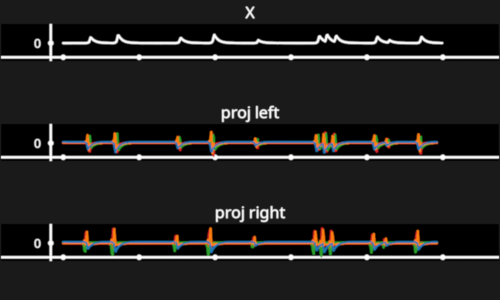

In [366]:
fig2 = fpl.Figure((3, 1), names=[["X", "proj left", "proj right"]], controller_ids="sync")

fig2["X"].add_line(X.ravel())
fig2["proj left"].add_line_collection(proj_left, cmap="tab10")
fig2["proj right"].add_line_collection(proj_right, cmap="tab10")

fig2.show(maintain_aspect=False)

In [367]:
proj_not = np.abs(proj_left[0]) * np.abs(proj_left[1])
# proj_not = proj_not.max() - proj_not

In [358]:
fig = fpl.Figure(cameras="3d", controller_types="orbit")

fig[0, 0].add_scatter(np.column_stack([proj_left.Tp:, 1]), sizes=5)
fig.show()

SyntaxError: invalid syntax (4251455768.py, line 3)

In [359]:
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering, AffinityPropagation
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [360]:
from sklearn.metrics import pairwise_distances

In [361]:
scaler = StandardScaler()

In [362]:
proj_cov = (scaler.fit_transform(proj_left.T) @ scaler.fit_transform(proj_right.T).T) / proj_left.shape[1]

<Axes: >

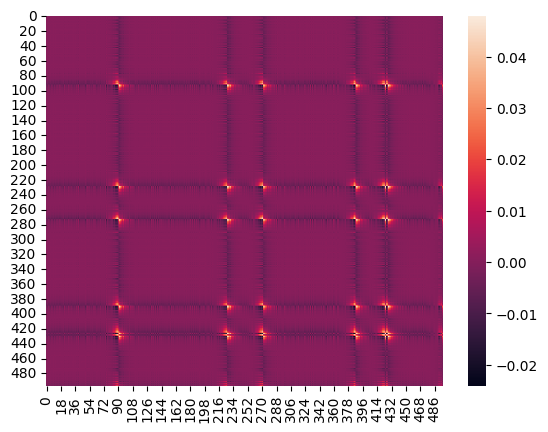

In [363]:
sns.heatmap(proj_cov)

In [364]:
proj_cov.shape

(497, 497)

In [365]:
proj_left.shape

(2, 497)

In [366]:
B = (proj_cov + proj_cov.T) / 2

In [367]:
km = KMeans(3)

km.fit(proj_left.T)

labels = km.labels_

In [368]:
fig3 = fpl.Figure(size=(1800, 600))

# fig3[0, 0].add_line(X_clean.ravel()[:-3], colors="red", alpha=0.5)
lg = fig3[0, 0].add_line(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-3]]), cmap="tab10", cmap_transform=labels)
lg_s = fig3[0, 0].add_scatter(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-3]]), sizes=7, cmap="tab10", cmap_transform=labels)

fig4 = fpl.Figure((1, 3), names=["left", "right", "Q"])

sg_left = fig4[0, 0].add_scatter(proj_left.T, sizes=7, cmap="tab10", cmap_transform=labels)
sg_right = fig4[0, 1].add_scatter(proj_right.T, sizes=7, cmap="tab10", cmap_transform=labels)

# fig5 = fpl.Figure(cameras="3d", controller_types="orbit")

# sg_Q = fig5[0, 0].add_scatter(Qk, sizes=5, cmap="tab10", cmap_transform=labels)

for subplot in fig4:
    subplot.axes.intersection = (0, 0, 0)

selector = lg.add_linear_selector()

@selector.add_event_handler("selection")
def set_point(ev):
    ix = ev.get_selected_index()
    sg_left.cmap = "tab10"
    sg_right.cmap = "tab10"
    sg_Q.cmap = "tab10"

    sg_left.colors[ix] = "w"
    sg_right.colors[ix] = "w"
    sg_Q.colors[ix] = "w"

def scatter_click_handler(ev):
    ix = ev.pick_info["vertex_index"]

    sg_left.cmap = "tab10"
    sg_right.cmap = "tab10"
    sg_Q.cmap = "tab10"

    sg_left.colors[ix] = "w"
    sg_right.colors[ix] = "w"
    sg_Q.colors[ix] = "w"
    
    selector.selection = ix

sg_left.add_event_handler(scatter_click_handler, "click")
sg_right.add_event_handler(scatter_click_handler, "click")

VBox([fig3.show(maintain_aspect=False), fig4.show()])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

NameError: name 'VBox' is not defined

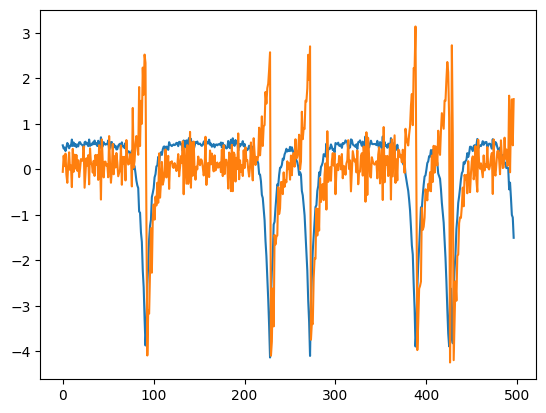

In [369]:
plt.plot(proj_left.T)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
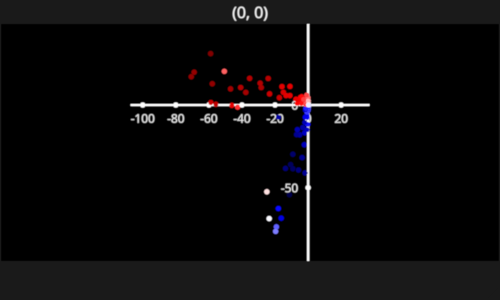

In [370]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

fig = fpl.Figure()
fig[0, 0].axes.intersection = (0, 0, 0)
fig[0, 0].add_scatter(proj_left.T ** 3, cmap="seismic", cmap_transform=(np.gradient(X.ravel()[:-3])), sizes=5)
fig.show()

In [371]:
from sklearn.preprocessing import PowerTransformer

In [372]:
scaled = PowerTransformer().fit_transform(proj_left.T)
fig[0, 0].graphics[0].data[:, :-1] = scaled

In [373]:
from sklearn.preprocessing import MinMaxScaler

In [374]:
agg = AgglomerativeClustering(3, metric="l1", linkage="complete")
agg.fit(MinMaxScaler().fit_transform(proj_left.T))
labels = agg.labels_

lg.cmap = "tab10"
lg.cmap.transform = labels
lg_s.cmap.transform = labels
lg_s.cmap = "tab10"

sg_left.cmap.transform = labels
sg_left.cmap = "tab10"
sg_right.cmap.transform = labels
sg_right.cmap = "tab10"

In [375]:
from deeptime.basis import Monomials

In [376]:
Y = Monomials(p=2, d=2)(H[:2].T)

mu0 = np.mean(Y[:-lag,:])
mu1 = np.mean(Y[lag:,:])
Past = Y[:-lag,:]
Future = Y[lag:,:]

# covariance matrices
C00 = (Past - mu0).T@(Past - mu0)/(Past.shape[0] - 1)
C11 = (Future - mu1).T@(Future - mu1)/(Future.shape[0] - 1)
C01 = (Past - mu0).T@(Future - mu1)/(Past.shape[0] - 1)
C00_half = linalg.sqrtm(C00)
C11_half = linalg.sqrtm(C11)

K = np.linalg.pinv(C00)@C01

# half-weighted koopman
Kbar = np.linalg.pinv(C00_half)@C01@np.linalg.pinv(C11_half)
# SVD 
U, S, Vh = np.linalg.svd(Kbar,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec = np.linalg.pinv(C00_half)@U
right_vec = np.linalg.pinv(C11_half)@Vh.T

# projection of data onto left and right singular vectors
proj_left = left_vec.T @ (Past.T - mu0)
proj_right = right_vec.T @ (Future.T - mu1)

Text(0.5, 1.0, 'right')

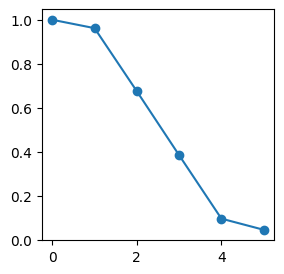

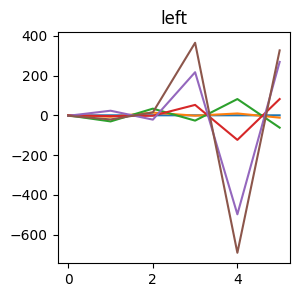

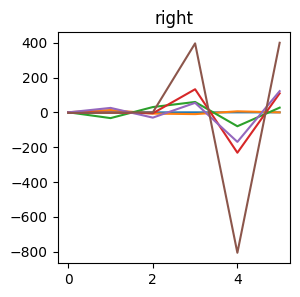

In [377]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec)
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec)
plt.title("right")

Text(0.5, 1.0, 'proj left')

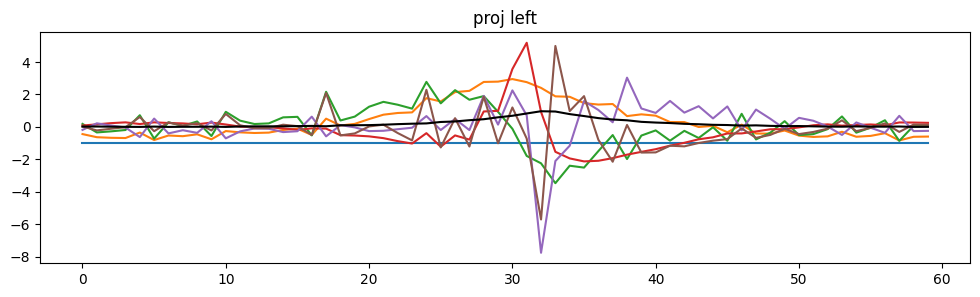

In [379]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_left.T[peak_ixs])
plt.plot(X.ravel()[peak_ixs], c="k")
plt.title("proj left")

Text(0.5, 1.0, 'proj right')

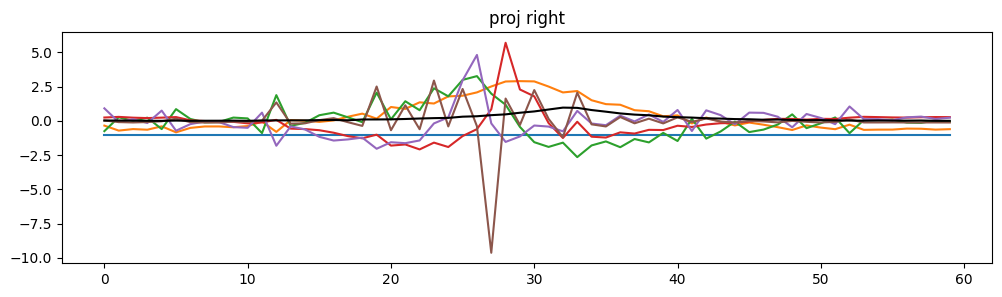

In [380]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_right.T[peak_ixs])
plt.plot(X.ravel()[peak_ixs], c="k")
plt.title("proj right")

In [381]:
import numpy as np

In [382]:
pos = np.asarray([1, 2, 3])

In [308]:
pos.shape

(3,)

In [309]:
pos.size in [2, 3]

True

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
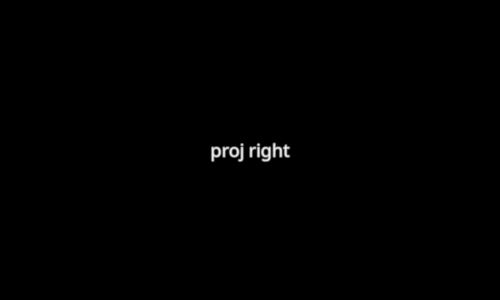

In [332]:
fig2 = fpl.Figure((3, 1), names=[["X", "proj left", "proj right"]], controller_ids="sync")

fig2["X"].add_line(X.ravel())

fig2["proj left"].add_line_collection(proj_left, cmap="tab20", alpha=0.5)
fig2["proj left"].add_line(X.ravel())
fig2["proj right"].add_line_collection(proj_right, cmap="tab20", alpha=0.5)
fig2["proj right"].add_line(X.ravel())

fig2.show(maintain_aspect=False)

In [333]:
from sklearn.cluster import KMeans

In [334]:
km = KMeans(3)

In [335]:
proj_left.shape

(6, 495)

In [336]:
proj_right.shape

(6, 495)

In [337]:
max_k = 4

In [338]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer

<Axes: >

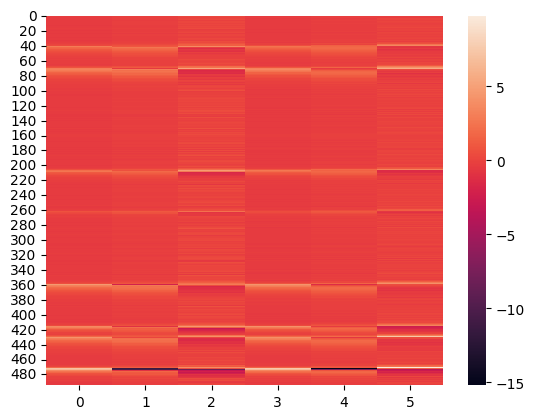

In [346]:
features = np.hstack([proj_left.T[:, 1:max_k], proj_right.T[:, 1:max_k]])
sns.heatmap(features)

In [347]:
labels = km.fit_predict(features)

In [348]:
labels.shape

(495,)

In [349]:
proj_left.shape

(6, 495)

In [350]:
proj_left.T.shape

(495, 6)

In [356]:
fig3 = fpl.Figure(size=(1800, 600))

# fig3[0, 0].add_line(X_clean.ravel()[:-3], colors="red", alpha=0.5)
lg = fig3[0, 0].add_line(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-5]]), cmap="tab10", cmap_transform=labels)
lg_s = fig3[0, 0].add_scatter(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-5]]), sizes=7, cmap="tab10", cmap_transform=labels)

fig4 = fpl.Figure((1, 2), cameras="3d", controller_types="orbit", names=["left", "right"])

sg_left = fig4[0, 0].add_scatter(proj_left.T[:, 1:4], sizes=7, cmap="tab10", cmap_transform=labels)
sg_right = fig4[0, 1].add_scatter(proj_right.T[:, 1:4], sizes=7, cmap="tab10", cmap_transform=labels)

# fig5 = fpl.Figure(cameras="3d", controller_types="orbit")

# sg_Q = fig5[0, 0].add_scatter(Qk, sizes=5, cmap="tab10", cmap_transform=labels)

for subplot in fig4:
    subplot.axes.intersection = (0, 0, 0)

selector = lg.add_linear_selector()

@selector.add_event_handler("selection")
def set_point(ev):
    ix = ev.get_selected_index()
    sg_left.cmap = "tab10"
    sg_right.cmap = "tab10"
    sg_Q.cmap = "tab10"

    sg_left.colors[ix] = "w"
    sg_right.colors[ix] = "w"
    sg_Q.colors[ix] = "w"

def scatter_click_handler(ev):
    ix = ev.pick_info["vertex_index"]

    sg_left.cmap = "tab10"
    sg_right.cmap = "tab10"
    sg_Q.cmap = "tab10"

    sg_left.colors[ix] = "w"
    sg_right.colors[ix] = "w"
    sg_Q.colors[ix] = "w"
    
    selector.selection = ix

sg_left.add_event_handler(scatter_click_handler, "click")
sg_right.add_event_handler(scatter_click_handler, "click")

VBox([fig3.show(maintain_aspect=False), fig4.show()])

RFBOutputContext()

RFBOutputContext()